In [1]:
import os
import glob
import numpy as np
import cv2

from scipy import io as sio
from skimage.filters import sobel
from skimage.color import rgb2gray

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    classification_report
)

import matplotlib.pyplot as plt

print("All imports successful!")


All imports successful!


In [2]:
import os

print("Current working directory:")
print(os.getcwd())


Current working directory:
c:\Users\UG1\AppData\Local\Programs\Microsoft VS Code


In [3]:
import os

DATA_ROOT = r"C:\Users\UG1\Downloads\archive"

print("Dataset root:")
print(DATA_ROOT)

print("\nContents:")
print(os.listdir(DATA_ROOT))


Dataset root:
C:\Users\UG1\Downloads\archive

Contents:
['ground_truth', 'images']


In [6]:
# =========================
# DATASET CONFIGURATION
# =========================

DATA_ROOT = r"C:\Users\UG1\Downloads\archive"

IMAGES_DIR = os.path.join(
    DATA_ROOT,
    "images",
    "train"
)

GT_DIR = os.path.join(
    DATA_ROOT,
    "ground_truth",
    "train"
)

# Number of images we want to use
N_IMAGES_TO_USE = 15

# Number of pixels sampled from each image
# 2000 edge + 2000 non-edge
PIXELS_PER_IMAGE = 4000

# For reproducible random sampling
RANDOM_STATE = 42

print("Images:", IMAGES_DIR)
print("Ground truth:", GT_DIR)


Images: C:\Users\UG1\Downloads\archive\images\train
Ground truth: C:\Users\UG1\Downloads\archive\ground_truth\train


In [7]:
def load_ground_truth_mat(mat_path, debug=False):

    # Load the MATLAB .mat file
    mat = sio.loadmat(
        mat_path,
        squeeze_me=True,
        struct_as_record=False
    )

    # Extract the groundTruth object
    gt = mat["groundTruth"]

    if debug:
        print("groundTruth type:", type(gt))
        print("groundTruth shape:", getattr(gt, "shape", "N/A"))

    # Store each human's boundary map
    boundary_maps = []

    # Go through every human annotator
    for annotator in np.atleast_1d(gt):

        # Get that person's boundary map
        boundaries = annotator.Boundaries

        boundary_maps.append(
            np.asarray(boundaries, dtype=np.float32)
        )

    if debug:
        print("Number of annotators:", len(boundary_maps))

        if boundary_maps:
            print(
                "Boundary shape:",
                boundary_maps[0].shape
            )

    # Average the annotations
    avg_boundary = np.mean(
        boundary_maps,
        axis=0
    )

    # Convert average boundary into binary labels
    binary_edges = (
        avg_boundary > 0.3
    ).astype(np.uint8)

    if debug:
        print(
            "Edge pixels:",
            binary_edges.sum()
        )

        print(
            "Non-edge pixels:",
            (binary_edges == 0).sum()
        )

    return binary_edges


In [ ]:
def extract_features(img_bgr):

    # 1. Convert BGR → RGB
   
    img_rgb = cv2.cvtColor(
        img_bgr,
        cv2.COLOR_BGR2RGB
    ).astype(np.float32) / 255.0

    gray = rgb2gray(img_rgb)

    grad_mag = sobel(gray)

    mean = cv2.blur(
        gray,
        (5, 5)
    )

    mean_sq = cv2.blur(
        gray ** 2,
        (5, 5)
    )

    local_std = np.sqrt(
        np.maximum(
            mean_sq - mean ** 2,
            0
        )
    )

    features = np.dstack([
        img_rgb[:, :, 0],  # R
        img_rgb[:, :, 1],  # G
        img_rgb[:, :, 2],  # B
        gray,              # grayscale
        grad_mag,          # gradient
        local_std          # texture
    ])

    return features


In [9]:
def build_dataset(
    images_dir,
    gt_dir,
    n_images,
    pixels_per_image,
    seed,
    debug=False
):

    # Random number generator
    rng = np.random.RandomState(seed)

    # Find image files
    image_paths = sorted(
        glob.glob(
            os.path.join(
                images_dir,
                "*.jpg"
            )
        )
    )[:n_images]

    print(
        f"Found {len(image_paths)} candidate images."
    )

    # Lists to store the final dataset
    X_list = []
    y_list = []

    # Process each image
    for img_path in image_paths:

        # --------------------------------
        # Find matching ground truth
        # --------------------------------

        base_name = os.path.splitext(
            os.path.basename(img_path)
        )[0]

        mat_path = os.path.join(
            gt_dir,
            base_name + ".mat"
        )

        # Skip if ground truth doesn't exist
        if not os.path.exists(mat_path):

            print(
                f"[skip] {base_name}: "
                "ground truth not found"
            )

            continue

        # --------------------------------
        # Load image
        # --------------------------------

        img = cv2.imread(img_path)

        if img is None:

            print(
                f"[skip] {base_name}: "
                "image could not be loaded"
            )

            continue

        # --------------------------------
        # Load ground truth
        # --------------------------------

        try:

            edges = load_ground_truth_mat(
                mat_path,
                debug=debug
            )

        except Exception as e:

            print(
                f"[skip] {base_name}: "
                f"ground truth error: {e}"
            )

            continue

        # --------------------------------
        # Extract features
        # --------------------------------

        features = extract_features(img)

        # --------------------------------
        # Find edge and non-edge pixels
        # --------------------------------

        edge_idx = np.argwhere(
            edges == 1
        )

        non_edge_idx = np.argwhere(
            edges == 0
        )

        # --------------------------------
        # Balanced sampling
        # --------------------------------

        n_each = pixels_per_image // 2

        if (
            len(edge_idx) == 0
            or
            len(non_edge_idx) == 0
        ):

            print(
                f"[skip] {base_name}: "
                "one class is empty"
            )

            continue

        print(
            f"[ok] {base_name}: "
            f"edge={len(edge_idx)}, "
            f"non-edge={len(non_edge_idx)}"
        )

        # Randomly select edge pixels
        edge_sample = edge_idx[
            rng.choice(
                len(edge_idx),
                min(
                    n_each,
                    len(edge_idx)
                ),
                replace=False
            )
        ]

        # Randomly select non-edge pixels
        non_edge_sample = non_edge_idx[
            rng.choice(
                len(non_edge_idx),
                min(
                    n_each,
                    len(non_edge_idx)
                ),
                replace=False
            )
        ]

        # --------------------------------
        # Add edge samples to X and y
        # --------------------------------

        for r, c in edge_sample:

            X_list.append(
                features[r, c, :]
            )

            y_list.append(1)

        # --------------------------------
        # Add non-edge samples
        # --------------------------------

        for r, c in non_edge_sample:

            X_list.append(
                features[r, c, :]
            )

            y_list.append(0)

    # Convert lists → NumPy arrays
    X = np.array(X_list)
    y = np.array(y_list)

    return X, y


In [10]:
X, y = build_dataset(
    IMAGES_DIR,
    GT_DIR,
    N_IMAGES_TO_USE,
    PIXELS_PER_IMAGE,
    RANDOM_STATE,
    debug=True
)


Found 15 candidate images.
groundTruth type: <class 'numpy.ndarray'>
groundTruth shape: (6,)
Number of annotators: 6
Boundary shape: (321, 481)
Edge pixels: 3857
Non-edge pixels: 150544
[ok] 100075: edge=3857, non-edge=150544
groundTruth type: <class 'numpy.ndarray'>
groundTruth shape: (5,)
Number of annotators: 5
Boundary shape: (481, 321)
Edge pixels: 2029
Non-edge pixels: 152372
[ok] 100080: edge=2029, non-edge=152372
groundTruth type: <class 'numpy.ndarray'>
groundTruth shape: (5,)
Number of annotators: 5
Boundary shape: (321, 481)
Edge pixels: 4164
Non-edge pixels: 150237
[ok] 100098: edge=4164, non-edge=150237
groundTruth type: <class 'numpy.ndarray'>
groundTruth shape: (6,)
Number of annotators: 6
Boundary shape: (321, 481)
Edge pixels: 2879
Non-edge pixels: 151522
[ok] 103041: edge=2879, non-edge=151522
groundTruth type: <class 'numpy.ndarray'>
groundTruth shape: (7,)
Number of annotators: 7
Boundary shape: (481, 321)
Edge pixels: 2898
Non-edge pixels: 151503
[ok] 104022: edge=

In [11]:
print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nFirst 5 feature rows:")
print(X[:5])

print("\nFirst 20 labels:")
print(y[:20])

print("\nPositive rate:")
print(y.mean())


X shape: (58560, 6)
y shape: (58560,)

First 5 feature rows:
[[0.1882353  0.3254902  0.34117648 0.29745454 0.01951826 0.02970939]
 [0.14901961 0.28627452 0.25882354 0.25512862 0.16573082 0.09666944]
 [0.11372549 0.14117648 0.10980392 0.13308118 0.02133693 0.06396953]
 [0.05490196 0.20784314 0.20392157 0.17506039 0.0678633  0.05649538]
 [0.16862746 0.32941177 0.29803923 0.29298314 0.00813913 0.01677101]]

First 20 labels:
[1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1]

Positive rate:
0.48770491803278687


In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training X:", X_train.shape)
print("Testing X:", X_test.shape)

print("Training y:", y_train.shape)
print("Testing y:", y_test.shape)


Training X: (43920, 6)
Testing X: (14640, 6)
Training y: (43920,)
Testing y: (14640,)


In [13]:
scaler = StandardScaler()

X_train_s = scaler.fit_transform(X_train)

X_test_s = scaler.transform(X_test)

print("Original first training sample:")
print(X_train[0])

print("\nScaled first training sample:")
print(X_train_s[0])


Original first training sample:
[0.80784315 0.67058825 0.5058824  0.6878796  0.01141337 0.05026748]

Scaled first training sample:
[ 1.7404407   1.1900901   0.685539    1.3118846  -0.7314544  -0.36011904]


In [14]:
models = {

    "Logistic Regression":
        LogisticRegression(
            max_iter=1000,
            random_state=RANDOM_STATE
        ),

    "SVM (RBF kernel)":
        SVC(
            kernel="rbf",
            probability=True,
            random_state=RANDOM_STATE
        )
}

print(models)


{'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42), 'SVM (RBF kernel)': SVC(probability=True, random_state=42)}



Training Logistic Regression...
              precision    recall  f1-score   support

    Non-Edge       0.69      0.81      0.75      7500
        Edge       0.75      0.63      0.68      7140

    accuracy                           0.72     14640
   macro avg       0.72      0.72      0.71     14640
weighted avg       0.72      0.72      0.72     14640


Training SVM (RBF kernel)...


C:\Users\UG1\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


              precision    recall  f1-score   support

    Non-Edge       0.76      0.76      0.76      7500
        Edge       0.75      0.74      0.74      7140

    accuracy                           0.75     14640
   macro avg       0.75      0.75      0.75     14640
weighted avg       0.75      0.75      0.75     14640



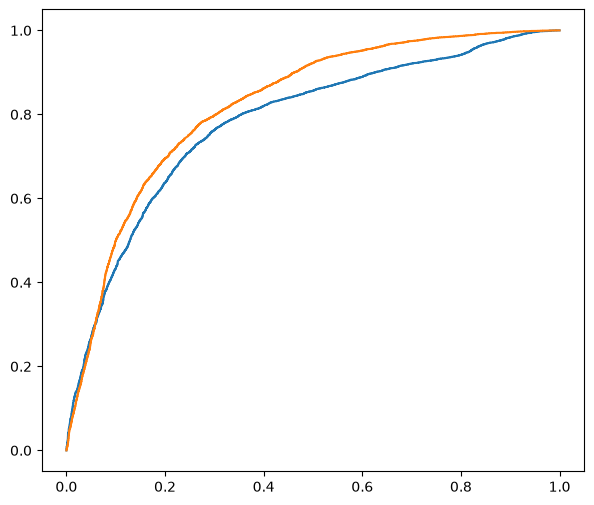

In [15]:
results = {}

plt.figure(figsize=(7, 6))

for name, model in models.items():

    print(f"\nTraining {name}...")

    # Train
    model.fit(
        X_train_s,
        y_train
    )

    # Predict class
    y_pred = model.predict(
        X_test_s
    )

    # Predict probability of Edge
    y_proba = model.predict_proba(
        X_test_s
    )[:, 1]

    # -------------------------
    # Metrics
    # -------------------------

    acc = accuracy_score(
        y_test,
        y_pred
    )

    precision = precision_score(
        y_test,
        y_pred
    )

    recall = recall_score(
        y_test,
        y_pred
    )

    f1 = f1_score(
        y_test,
        y_pred
    )

    roc_auc = roc_auc_score(
        y_test,
        y_proba
    )

    # Store results
    results[name] = {
        "Accuracy": acc,
        "Precision": precision,
        "Recall": recall,
        "F1": f1,
        "ROC-AUC": roc_auc
    }

    # Print classification report
    print(
        classification_report(
            y_test,
            y_pred,
            target_names=[
                "Non-Edge",
                "Edge"
            ]
        )
    )

    # -------------------------
    # ROC curve
    # -------------------------

    fpr, tpr, _ = roc_curve(
        y_test,
        y_proba
    )

    plt.plot(
        fpr,
        tpr,
        label=f"{name} (AUC={roc_auc:.3f})"
    )


In [17]:
print("=" * 70)

print(
    f"{'Metric':<12}"
    + "".join(
        f"{name:>25}"
        for name in results
    )
)

print("=" * 70)

for metric in [
    "Accuracy",
    "Precision",
    "Recall",
    "F1",
    "ROC-AUC"
]:

    row = f"{metric:<12}"

    for name in results:

        row += (
            f"{results[name][metric]:>25.4f}"
        )

    print(row)

print("=" * 70)


Metric            Logistic Regression         SVM (RBF kernel)
Accuracy                       0.7181                   0.7516
Precision                      0.7546                   0.7462
Recall                         0.6254                   0.7434
F1                             0.6839                   0.7448
ROC-AUC                        0.7813                   0.8220
